# Quickstart: NOAA RRFS, RRFS ENS, and REFS forecasts, virtual - dynamical.org Icechunk Zarr

NOAA's Rapid Refresh Forecast System family provides convection-allowing forecasts on a 3 km grid covering the contiguous United States. These six datasets offer 15-minute storm evolution, forecasts through 84 hours, six individual members, and REFS ensemble statistics and precipitation probabilities.

Deterministic forecasts:
- RRFS sub-hourly: https://dynamical.org/catalog/noaa-rrfs-forecast-sub-hourly-virtual/
- RRFS 18 hour: https://dynamical.org/catalog/noaa-rrfs-forecast-18-hour-virtual/
- RRFS 84 hour: https://dynamical.org/catalog/noaa-rrfs-forecast-84-hour-virtual/

Ensemble forecasts:
- RRFS ENS: https://dynamical.org/catalog/noaa-rrfs-ens-forecast-virtual/

Ensemble summary products:
- REFS hourly: https://dynamical.org/catalog/noaa-refs-forecast-hourly-virtual/
- REFS 3 hourly: https://dynamical.org/catalog/noaa-refs-forecast-3-hourly-virtual/

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install 'dynamical-catalog>=1.0.1' 'gribberish>=1.8.4' cartopy rioxarray

In [2]:
import dynamical_catalog
import xarray as xr

sub_hourly = dynamical_catalog.open("noaa-rrfs-forecast-sub-hourly-virtual", chunks=None)
rrfs_18h = dynamical_catalog.open("noaa-rrfs-forecast-18-hour-virtual", chunks=None)
rrfs_84h = dynamical_catalog.open("noaa-rrfs-forecast-84-hour-virtual", chunks=None)
members = dynamical_catalog.open("noaa-rrfs-ens-forecast-virtual", chunks=None)
refs_hourly = dynamical_catalog.open("noaa-refs-forecast-hourly-virtual", chunks=None)
refs_3hourly = dynamical_catalog.open("noaa-refs-forecast-3-hourly-virtual", chunks=None)
rrfs_18h

<xarray.Dataset> Size: 44TB
Dimensions:                                                                                     (
                                                                                                 init_time: 521,
                                                                                                 lead_time: 19,
                                                                                                 y: 1059,
                                                                                                 x: 1799)
Coordinates:
  * init_time                                                                                   (init_time) datetime64[ns] 4kB ...
    expected_forecast_length                                                                    (init_time) timedelta64[us] 4kB ...
  * lead_time                                                                                   (lead_time) timedelta64[us] 152B ...
    valid_time                                                                                  (init_time, lead_time) datetime64[ns] 79kB ...
  * y                                                                                           (y) float64 8kB ...
  * x                                                                                           (x) float64 14kB ...
    longitude                                                                                   (y, x) float32 8MB ...
    latitude                                                                                    (y, x) float32 8MB ...
    spatial_ref                                                                                 int64 8B ...
Data variables: (12/292)
    aerosol_emission_flux_atmosphere_dust_dry_below_10um                                        (init_time, lead_time, y, x) float64 151GB ...
    aerosol_emission_flux_atmosphere_particulate_organic_matter_dry_below_2p5um                 (init_time, lead_time, y, x) float64 151GB ...
    average_mass_density_8m_total_aerosol_below_10um                                            (init_time, lead_time, y, x) float64 151GB ...
    best_4_layer_lifted_index_180_0mb                                                           (init_time, lead_time, y, x) float64 151GB ...
    brightness_temperature_goes_16_band_11                                                      (init_time, lead_time, y, x) float64 151GB ...
    aerosol_optical_thickness_atmosphere                                                        (init_time, lead_time, y, x) float64 151GB ...
    ...                                                                                          ...
    wind_v_90_60mb                                                                              (init_time, lead_time, y, x) float64 151GB ...
    wind_v_planetary_boundary_layer                                                             (init_time, lead_time, y, x) float64 151GB ...
    wind_v_180_150mb                                                                            (init_time, lead_time, y, x) float64 151GB ...
    wind_v_max_wind                                                                             (init_time, lead_time, y, x) float64 151GB ...
    wind_v_tropopause                                                                           (init_time, lead_time, y, x) float64 151GB ...
    wind_v_80m                                                                                  (init_time, lead_time, y, x) float64 151GB ...
Attributes:
    dataset_id:           noaa-rrfs-forecast-18-hour-virtual
    dataset_version:      0.1.0
    name:                 NOAA RRFS forecast, 18 hour, virtual
    description:          Weather forecasts from the Rapid Refresh Forecast S...
    attribution:          NOAA NWS NCEP RRFS data processed by dynamical.org ...
    license:              CC-BY-4.0
    spatial_domain:       Continental United States
    spatial_resolution:   3 km
    time_domai

Each dataset has two time dimensions: `init_time`, when a forecast run began, and `lead_time`, how far that run extends into the future. Their sum is the two-dimensional `valid_time` coordinate. RRFS ENS adds `ensemble_member`, and REFS stores means and standard deviations along `statistic`.

All six share a 3 km Lambert Conformal grid indexed by projected `x` and `y`, with two-dimensional `latitude` and `longitude` coordinates. Surface variables live at the dataset root. Variables on vertical levels live in groups such as `pressure_level`, available in the RRFS 18-hour, 84-hour and RRFS ENS datasets.

## What does a 15-minute step add?

On the afternoon of 3 September 2026 a line of storms organized over northern Lower Michigan and moved into metro Detroit, where an [EF-2 tornado touched down at 20:14 UTC](https://www.weather.gov/dtx/severeweather0902032026). The sub-hourly dataset starts a run every hour and writes output every 15 minutes. Here is the RRFS run initialized at 12 UTC that morning, at Detroit, with the same run's hourly output from the 18 hour dataset.

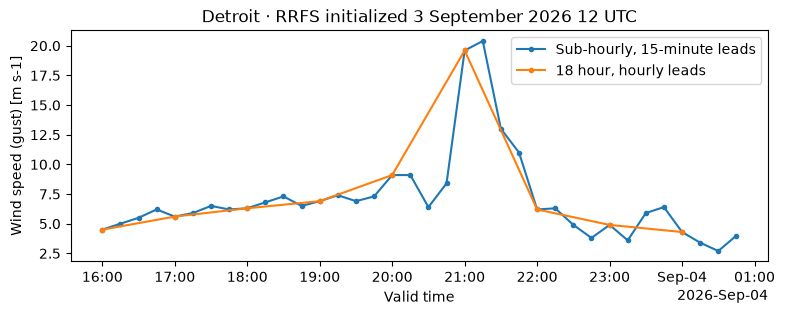

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import rioxarray  # enables the .rio accessor
from pyproj import Transformer

to_xy = Transformer.from_crs("EPSG:4326", sub_hourly.rio.crs, always_xy=True)
x, y = to_xy.transform(-83.05, 42.33)  # Detroit, Michigan

fig, ax = plt.subplots(figsize=(9, 3))
for ds, label in [
    (sub_hourly, "Sub-hourly, 15-minute leads"),
    (rrfs_18h, "18 hour, hourly leads"),
]:
    (
        ds["wind_gust_surface"]
        .sel(init_time="2026-09-03T12", lead_time=slice("4h", "12h"))
        .sel(x=x, y=y, method="nearest")
        .plot(ax=ax, x="valid_time", marker="o", markersize=3, label=label)
    )
ax.set_title("Detroit · RRFS initialized 3 September 2026 12 UTC")
ax.legend();

Every 15-minute frame of the same run shows the storms develop over Lake Michigan and northern Lower Michigan and grow into a line that sweeps southeast across the state. Composite reflectivity is the model's simulated radar, not an observed radar mosaic.

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

crs = sub_hourly.spatial_ref.attrs
projection = ccrs.LambertConformal(
    central_longitude=crs["longitude_of_central_meridian"],
    central_latitude=crs["latitude_of_projection_origin"],
    standard_parallels=crs["standard_parallel"],
    globe=ccrs.Globe(semimajor_axis=crs["semi_major_axis"], semiminor_axis=crs["semi_minor_axis"]),
)
storms = (
    sub_hourly["composite_reflectivity"]
    .sel(init_time="2026-09-03T12", lead_time=slice("2h", "10h"))
    .rio.clip_box(-87.5, 41.5, -81.5, 45.5, crs="EPSG:4326")
    .load()
)
storms = storms.where(storms > 5)  # hide the no-echo background

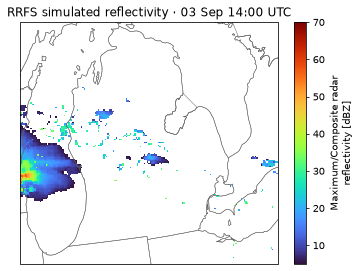

In [5]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots(figsize=(6, 4.5), dpi=70, subplot_kw={"projection": projection})
ax.add_feature(cfeature.STATES, edgecolor="0.4", linewidth=0.5)
ax.add_feature(cfeature.LAKES, facecolor="none", edgecolor="0.4", linewidth=0.5)
mesh = storms.isel(lead_time=0).plot(ax=ax, transform=projection, cmap="turbo", vmin=5, vmax=70)

def update(i):
    frame = storms.isel(lead_time=i)
    mesh.set_array(frame.values.ravel())
    ax.set_title(f"RRFS simulated reflectivity · {frame.valid_time.dt.strftime('%d %b %H:%M UTC').item()}")

anim = FuncAnimation(fig, update, frames=storms.sizes["lead_time"], interval=200)
HTML(anim.to_jshtml())

## How did the ensemble's view of a landfall change?

[Hurricane Isaias](https://en.wikipedia.org/wiki/Hurricane_Isaias_(2026)) made landfall near Destin, Florida, at 01:30 UTC on 10 October 2026. RRFS ENS runs six members every six hours; member 0 is the deterministic RRFS forecast. Below are the full forecasts at Destin from five runs 12 hours apart, colored by initialization time.

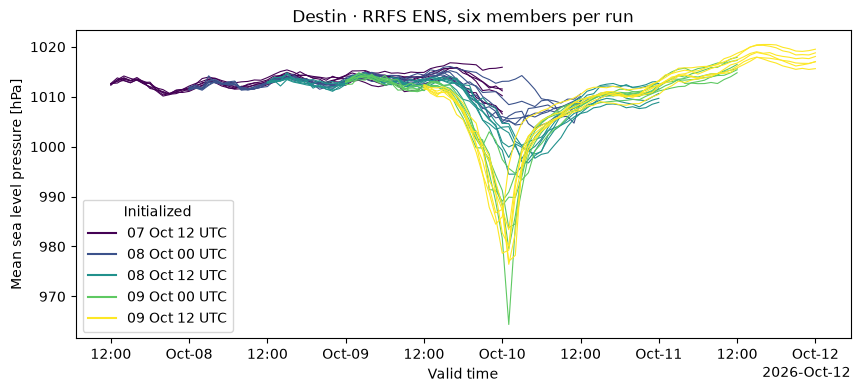

In [6]:
import pandas as pd

x, y = to_xy.transform(-86.50, 30.39)  # Destin, Florida
init_times = pd.date_range("2026-10-07T12", "2026-10-09T12", freq="12h")
pressure = (
    members["pressure_reduced_to_mean_sea_level"]
    .sel(init_time=init_times)
    .sel(x=x, y=y, method="nearest")
    .load()
    / 100
)
pressure.attrs = {"long_name": "Mean sea level pressure", "units": "hPa"}

fig, ax = plt.subplots(figsize=(10, 4))
for init_time, color in zip(init_times, plt.cm.viridis(np.linspace(0, 1, len(init_times)))):
    pressure.sel(init_time=init_time).plot(
        ax=ax, x="valid_time", hue="ensemble_member", color=color, linewidth=0.8, add_legend=False,
    )
    ax.plot([], [], color=color, label=f"{init_time:%d %b %H} UTC")
ax.legend(title="Initialized")
ax.set_title("Destin · RRFS ENS, six members per run");

## What does the hurricane look like in the vertical?

Variables on vertical levels are in separate groups; the 84 hour dataset's `pressure_level` group has 45 levels from 1000 to 2 hPa. Ninety minutes before landfall, the run initialized 9 October 18 UTC puts Isaias's center just off the Florida Panhandle. A west–east cut through its lowest sea level pressure shows the eye and the eyewall around it.

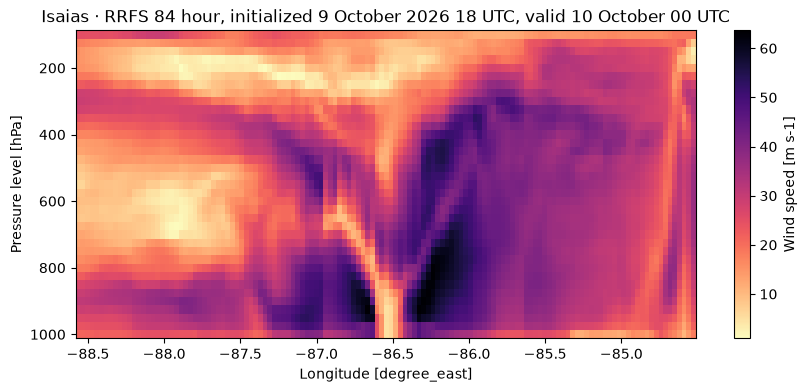

In [7]:
rrfs_84h_pressure = dynamical_catalog.open(
    "noaa-rrfs-forecast-84-hour-virtual", group="pressure_level", chunks=None
)

mslp = (
    rrfs_84h["pressure_reduced_to_mean_sea_level"]
    .sel(init_time="2026-10-09T18", lead_time="6h")
    .rio.clip_box(-89, 28, -84, 31.5, crs="EPSG:4326")
)
center = mslp.isel(mslp.argmin(dim=["x", "y"]))
x, y = float(center.x), float(center.y)

wind = (
    rrfs_84h_pressure[["wind_u", "wind_v"]]
    .sel(init_time="2026-10-09T18", lead_time="6h", y=y)
    .sel(x=slice(x - 200_000, x + 200_000), pressure_level=slice(100, 1000))
    .load()
)
speed = np.hypot(wind.wind_u, wind.wind_v)
speed.attrs = {"long_name": "Wind speed", "units": "m s-1"}
speed.plot(x="longitude", y="pressure_level", yincrease=False, cmap="magma_r", size=4, aspect=2.5)
plt.title("Isaias · RRFS 84 hour, initialized 9 October 2026 18 UTC, valid 10 October 00 UTC");

## How rare is the forecast rain?

REFS combines RRFS ENS members with time-lagged runs into products that the raw members don't provide, such as the probability that precipitation exceeds local flash flood guidance or the local 1- to 100-year average recurrence interval (ARI). During [record flooding in central Indiana](https://www.weather.gov/ind/august2026flooding), many flash flood reports came in during the early morning of 14 August 2026. These maps show neighborhood probabilities, the chance of an exceedance near each point, for the 24 hours ending 14 August 12 UTC.

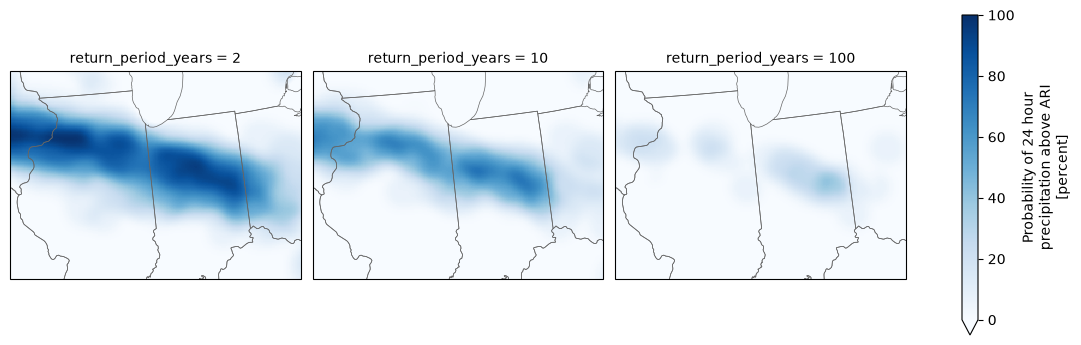

In [8]:
return_periods = [2, 10, 100]
ari = xr.concat(
    [
        refs_3hourly[f"neighborhood_probability_of_precipitation_exceeding_{n}_year_average_recurrence_interval_24_hour_surface"]
        .sel(init_time="2026-08-13T12", lead_time="24h")
        .rio.clip_box(-91.5, 38.5, -83.5, 42.5, crs="EPSG:4326")
        for n in return_periods
    ],
    dim=pd.Index(return_periods, name="return_period_years"),
).load()
ari.attrs = {"long_name": "Probability of 24 hour precipitation above ARI", "units": "percent"}

grid = ari.plot(
    col="return_period_years", transform=projection, subplot_kws={"projection": projection},
    cmap="Blues", vmin=0, vmax=100, size=3.5,
)
for ax in grid.axs.flat:
    ax.add_feature(cfeature.STATES, edgecolor="0.4", linewidth=0.5)

## Where is critical fire weather likely?

Some REFS probabilities combine variables. One is the probability of 10 m wind of at least 9 m s⁻¹ together with 2 m relative humidity of at most 20%, the two ingredients of critical fire weather. The season's first Santa Ana wind event brought [Red Flag Warnings to Los Angeles and Ventura counties from 15 to 17 October 2026](https://lacounty.gov/2026/10/14/los-angeles-county-public-safety-agencies-urge-residents-to-prepare-for-high-winds-significant-fire-risk/). Here is the run initialized the morning of 15 October, for late morning local time the next day.

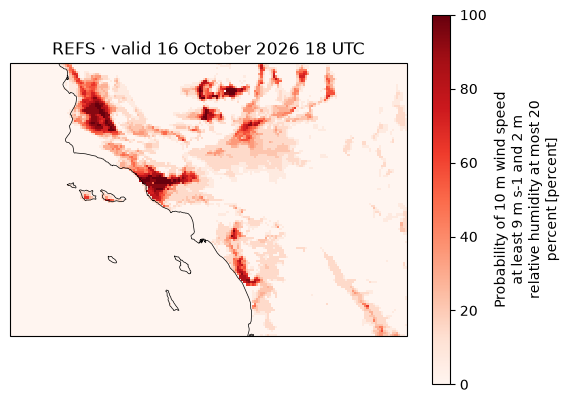

In [9]:
fire_weather = (
    refs_hourly["probability_of_wind_speed_10m_at_least_9_and_relative_humidity_2m_at_most_20"]
    .sel(init_time="2026-10-15T12", lead_time="30h")
    .rio.clip_box(-121, 33, -115.5, 35.5, crs="EPSG:4326")
)
ax = plt.subplot(projection=projection)
fire_weather.plot(ax=ax, transform=projection, cmap="Reds", vmin=0, vmax=100)
ax.coastlines(linewidth=0.5)
ax.set_title("REFS · valid 16 October 2026 18 UTC");

## Community challenge

- The sub-hourly dataset also stores `updraft_helicity_5000_2000m` every 15 minutes. Do the model's rotating storms on 3 September pass near the Detroit tornado track, and do successive hourly runs agree on where?
- How do REFS probabilities of exceeding flash flood guidance and recurrence-interval depths compare with observed rainfall, for example from the [NOAA MRMS CONUS analysis](https://dynamical.org/catalog/noaa-mrms-conus-analysis-hourly/), across this summer's flash floods?
- REFS also carries aviation probabilities: flight category, ceiling, visibility, icing and clear-air turbulence. How reliable are they at airports you care about?